# Running Example: The 5-Phase LSDM Framework

This notebook demonstrates the end-to-end execution of the Large-Scale Decision Making (LSDM) framework proposed in the paper. It simulates a prioritization scenario with **5 stakeholders** evaluating **3 candidate requirements** across **3 criteria** (C1, C2, C3), showcasing how the framework handles uncertainty, sparsity, and consensus-building.

In [1]:
# Import core framework modules for fuzzification, similarity calculation, recommender systems, clustering, and consensus feedback
import numpy as np
import pandas as pd
from src.fuzzification import convert_to_ifv_matrix, defuzzify_to_numeric, format_ifv
from src.similarity import get_similarity_matrices
from src.recommender import predict_missing_values
from src.clustering import get_top_k_neighbors, calculate_snn_matrices, classify_stakeholders
from src.feedback import calculate_group_recommendation, calculate_consensus_degree, calculate_classification
from src.visualization import plot_heatmap, plot_stakeholder_map

### Phase 1: Requirements Prioritization Problem Definition
In this initial phase, project experts define the evaluation criteria and establish the **Reference Priority Matrix (CPCRM)**, acting as an expert-defined benchmark for prioritization classes (Releases 1-4). Using an R-trapezoidal fuzzification function, numeric values are converted to IFVs to explicitly model the uncertainty and hesitation inherent in the decision-making process.

In [2]:
# Define the numeric Reference Priority Matrix mapping ideal criteria values to prioritization classes
cpcrm_data = {
    'Release1': [5, 5, 1],
    'Release2': [4, 3, 2],
    'Release3': [3, 2, 3],
    'Release4': [2, 1, 4]
}
df_cpcrm_num = pd.DataFrame(cpcrm_data, index=['C1', 'C2', 'C3'])
print("Reference Priority Matrix (Numeric Values):")
display(df_cpcrm_num)

# Apply the intuitionistic fuzzification function to transform numeric targets into IFVs
df_cpcrm_ifv = convert_to_ifv_matrix(df_cpcrm_num, method='r-trapezoidal_example', pi=0.1,
                                     scale_min=1.0, scale_max=5.0,
                                     trap_limit_min=1.5, trap_limit_max=4.5)
print("\nReference Priority Matrix (IFVs):")
display(df_cpcrm_ifv.map(format_ifv))

Reference Priority Matrix (Numeric Values):


,Release1,Release2,Release3,Release4
C1,5,4,3,2
C2,5,3,2,1
C3,1,2,3,4



Reference Priority Matrix (IFVs):


,Release1,Release2,Release3,Release4
C1,"(0.90, 0.00, 0.10)","(0.75, 0.15, 0.10)","(0.45, 0.45, 0.10)","(0.15, 0.75, 0.10)"
C2,"(0.90, 0.00, 0.10)","(0.45, 0.45, 0.10)","(0.15, 0.75, 0.10)","(0.00, 0.90, 0.10)"
C3,"(0.00, 0.90, 0.10)","(0.15, 0.75, 0.10)","(0.45, 0.45, 0.10)","(0.75, 0.15, 0.10)"


### Phase 2: Requirements Ratings Recommendations
To mitigate information overload and address data sparsity, this phase employs a collaborative filtering recommender system. Stakeholder ratings are fuzzified into IFVs, and pairwise similarities are calculated using the **H-max distance**. The system then predicts missing evaluations based on the preferences of similar stakeholders.

Numeric Ratings Matrix:


Req1           Req2           Req3          
      C1   C2   C3   C1   C2   C3   C1   C2   C3
St1  5.0  5.0  1.0  2.0  2.0  1.0  4.0  3.0  3.0
St2  4.0  5.0  2.0  4.0  3.0  2.0  1.0  2.0  1.0
St3  5.0  5.0  2.0  NaN  NaN  NaN  2.0  3.0  3.0
St4  NaN  NaN  NaN  4.0  5.0  4.0  2.0  1.0  2.0
St5  NaN  NaN  NaN  1.0  2.0  1.0  NaN  NaN  NaN


IFVs Ratings Matrix:


Req1                                          \
                     C1                  C2                  C3   
St1  (0.90, 0.00, 0.10)  (0.90, 0.00, 0.10)  (0.00, 0.90, 0.10)   
St2  (0.75, 0.15, 0.10)  (0.90, 0.00, 0.10)  (0.15, 0.75, 0.10)   
St3  (0.90, 0.00, 0.10)  (0.90, 0.00, 0.10)  (0.15, 0.75, 0.10)   
St4                 NaN                 NaN                 NaN   
St5                 NaN                 NaN                 NaN   

                   Req2                                          \
                     C1                  C2                  C3   
St1  (0.15, 0.75, 0.10)  (0.15, 0.75, 0.10)  (0.00, 0.90, 0.10)   
St2  (0.75, 0.15, 0.10)  (0.45, 0.45, 0.10)  (0.15, 0.75, 0.10)   
St3                 NaN                 NaN                 NaN   
St4  (0.75, 0.15, 0.10)  (0.90, 0.00, 0.10)  (0.75, 0.15, 0.10)   
St5  (0.00, 0.90, 0.10)  (0.15, 0.75, 0.10)  (0.00, 0.90, 0.10)   

                   Req3                                          
                     C1                  C2                  C3  
St1  (0.75, 0.15, 0.10)  (0.45, 0.45, 0.10)  (0.45, 0.45, 0.10)  
St2  (0.00, 0.90, 0.10)  (0.15, 0.75, 0.10)  (0.00, 0.90, 0.10)  
St3  (0.15, 0.75, 0.10)  (0.45, 0.45, 0.10)  (0.45, 0.45, 0.10)  
St4  (0.15, 0.75, 0.10)  (0.00, 0.90, 0.10)  (0.15, 0.75, 0.10)  
St5                 NaN                 NaN                 NaN


Similarity Matrix (SMSS):


,St1,St2,St3,St4,St5
St1,1.00,0.68,0.88,0.43,0.95
St2,0.68,1.00,0.82,0.75,0.60
St3,0.88,0.82,1.00,0.75,0.00
St4,0.43,0.75,0.75,1.00,0.25
St5,0.95,0.60,0.00,0.25,1.00


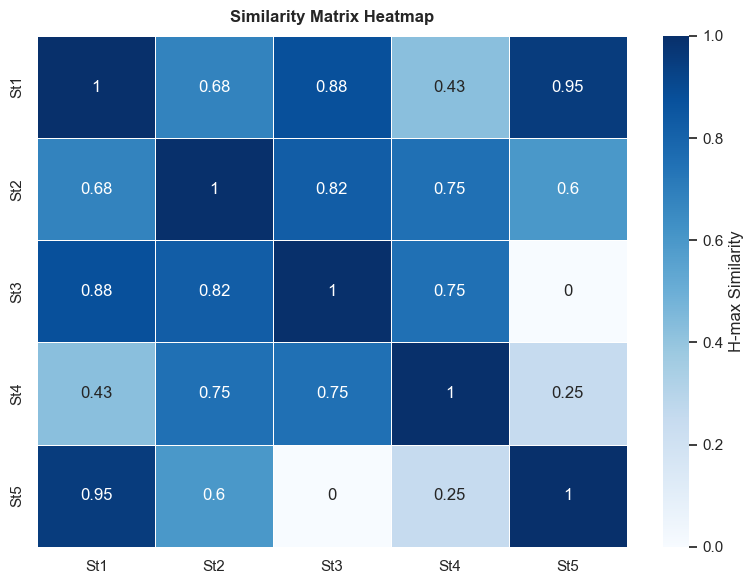


Predicted IFVs (Example showing completed profile for an incomplete stakeholder):


Req1                                          \
                     C1                  C2                  C3   
St4  (0.83, 0.07, 0.10)  (0.90, 0.00, 0.10)  (0.15, 0.75, 0.10)   

                   Req2                                          \
                     C1                  C2                  C3   
St4  (0.75, 0.15, 0.10)  (0.90, 0.00, 0.10)  (0.75, 0.15, 0.10)   

                   Req3                                          
                     C1                  C2                  C3  
St4  (0.15, 0.75, 0.10)  (0.00, 0.90, 0.10)  (0.15, 0.75, 0.10)

In [3]:
# Initialize the stakeholder numeric ratings matrix containing missing values (sparsity)
ratings_data = {
    ('Req1', 'C1'): [5.0, 4.0, 5.0, np.nan, np.nan], ('Req1', 'C2'): [5.0, 5.0, 5.0, np.nan, np.nan], ('Req1', 'C3'): [1.0, 2.0, 2.0, np.nan, np.nan],
    ('Req2', 'C1'): [2.0, 4.0, np.nan, 4.0, 1.0], ('Req2', 'C2'): [2.0, 3.0, np.nan, 5.0, 2.0], ('Req2', 'C3'): [1.0, 2.0, np.nan, 4.0, 1.0],
    ('Req3', 'C1'): [4.0, 1.0, 2.0, 2.0, np.nan], ('Req3', 'C2'): [3.0, 2.0, 3.0, 1.0, np.nan], ('Req3', 'C3'): [3.0, 1.0, 3.0, 2.0, np.nan]
}
df_initial_num = pd.DataFrame(ratings_data, index=['St1', 'St2', 'St3', 'St4', 'St5'])
df_initial_num.columns = pd.MultiIndex.from_tuples(df_initial_num.columns)
print("Numeric Ratings Matrix:")
display(df_initial_num)

# Transform continuous numeric ratings into Intuitionistic Fuzzy Values (IFVs)
df_initial_ifv = convert_to_ifv_matrix(df_initial_num, method='r-trapezoidal_example', pi=0.1,
                                       scale_min=1.0, scale_max=5.0,
                                       trap_limit_min=1.5, trap_limit_max=4.5)
print("\nIFVs Ratings Matrix:")
display(df_initial_ifv.map(format_ifv))

# Calculate the stakeholders' pairwise distance and similarity matrices using the H-max measure
dist_matrix, sim_matrix = get_similarity_matrices(df_initial_ifv)
print("\nSimilarity Matrix (SMSS):")
display(sim_matrix.round(2))
plot_heatmap(sim_matrix, title="Similarity Matrix Heatmap", filename='../results/running_example_similarity_matrix.png')

# Predict missing ratings to resolve data sparsity using a collaborative filtering approach
df_predicted_ifv = predict_missing_values(df_initial_ifv, sim_matrix, k=2, strategy='global')
print("\nPredicted IFVs (Example showing completed profile for an incomplete stakeholder):")
display(df_predicted_ifv.loc[['St4']].map(format_ifv))

### Phase 3: Stakeholders Clustering
This phase organizes stakeholders into preference groups using the **Shared Nearest Neighbor (SNN)** clustering algorithm. By evaluating the local density of shared neighbors, the framework identifies core stakeholders, who represent the majority view, and isolated stakeholders, who act as preference outliers requiring targeted feedback.

In [4]:
# Identify the top-k nearest neighbors for each stakeholder based on H-max similarity
neighbors_map = get_top_k_neighbors(sim_matrix, k=3)
print("Top Nearest Neighbors:")
for st, nb in neighbors_map.items():
    print(f"{st}: {nb}")

# Construct the Shared Nearest Neighbor (SNN) similarity and distance matrices
snn_sim, snn_dist = calculate_snn_matrices(neighbors_map, df_initial_num.index, k=3)
print("\nSNN Similarity Matrix:")
display(snn_sim)

print("\nSNN Distance Matrix:")
display(snn_dist)

# Evaluate SNN density to classify participants into core (majority) and isolated (outlier) groups
densities, core_list, isolated_list = classify_stakeholders(snn_sim, threshold=2.5)
print("\nSNN Density:")
display(densities.to_frame('Density'))

Top Nearest Neighbors:
St1: {'St5', 'St2', 'St3'}
St2: {'St1', 'St4', 'St3'}
St3: {'St1', 'St2', 'St4'}
St4: {'St2', 'St1', 'St3'}
St5: {'St1', 'St2', 'St4'}

SNN Similarity Matrix:


,St1,St2,St3,St4,St5
St1,3,1,1,0,1
St2,1,3,2,2,0
St3,1,2,3,2,0
St4,0,2,2,3,0
St5,1,0,0,0,3



SNN Distance Matrix:


,St1,St2,St3,St4,St5
St1,0,2,2,3,2
St2,2,0,1,1,3
St3,2,1,0,1,3
St4,3,1,1,0,3
St5,2,3,3,3,0



SNN Density:


,Density
St1,3
St2,5
St3,5
St4,4
St5,1


### Phase 4: Feedback and Preference Modification
When the group consensus is insufficient, the framework enters a feedback loop. A **Group Recommendation (GR)** is generated by aggregating the preferences of the core stakeholders. The **GR** acts as a targeted recommendation, guiding isolated participants to modify their preferences and align closer to the collective decision.

IFVs Ratings Matrix (Filled with Predicted Ratings):


Req1                                          \
                     C1                  C2                  C3   
St1  (0.90, 0.00, 0.10)  (0.90, 0.00, 0.10)  (0.00, 0.90, 0.10)   
St2  (0.75, 0.15, 0.10)  (0.90, 0.00, 0.10)  (0.15, 0.75, 0.10)   
St3  (0.90, 0.00, 0.10)  (0.90, 0.00, 0.10)  (0.15, 0.75, 0.10)   
St4  (0.83, 0.07, 0.10)  (0.90, 0.00, 0.10)  (0.15, 0.75, 0.10)   
St5  (0.84, 0.06, 0.10)  (0.90, 0.00, 0.10)  (0.06, 0.84, 0.10)   

                   Req2                                          \
                     C1                  C2                  C3   
St1  (0.15, 0.75, 0.10)  (0.15, 0.75, 0.10)  (0.00, 0.90, 0.10)   
St2  (0.75, 0.15, 0.10)  (0.45, 0.45, 0.10)  (0.15, 0.75, 0.10)   
St3  (0.44, 0.46, 0.10)  (0.30, 0.60, 0.10)  (0.07, 0.83, 0.10)   
St4  (0.75, 0.15, 0.10)  (0.90, 0.00, 0.10)  (0.75, 0.15, 0.10)   
St5  (0.00, 0.90, 0.10)  (0.15, 0.75, 0.10)  (0.00, 0.90, 0.10)   

                   Req3                                          
                     C1                  C2                  C3  
St1  (0.75, 0.15, 0.10)  (0.45, 0.45, 0.10)  (0.45, 0.45, 0.10)  
St2  (0.00, 0.90, 0.10)  (0.15, 0.75, 0.10)  (0.00, 0.90, 0.10)  
St3  (0.15, 0.75, 0.10)  (0.45, 0.45, 0.10)  (0.45, 0.45, 0.10)  
St4  (0.15, 0.75, 0.10)  (0.00, 0.90, 0.10)  (0.15, 0.75, 0.10)  
St5  (0.46, 0.44, 0.10)  (0.33, 0.57, 0.10)  (0.28, 0.62, 0.10)


IFV Group Recommendation:


Req1                                          \
                    C1                  C2                  C3   
GR  (0.84, 0.06, 0.10)  (0.90, 0.00, 0.10)  (0.11, 0.79, 0.10)   

                  Req2                                          \
                    C1                  C2                  C3   
GR  (0.52, 0.38, 0.10)  (0.45, 0.45, 0.10)  (0.24, 0.66, 0.10)   

                  Req3                                          
                    C1                  C2                  C3  
GR  (0.26, 0.64, 0.10)  (0.26, 0.64, 0.10)  (0.26, 0.64, 0.10)


Numeric Group Recommendation:


Req1           Req2           Req3          
     C1   C2   C3   C1   C2   C3   C1   C2   C3
GR  5.0  5.0  1.0  3.0  3.0  2.0  2.0  2.0  2.0

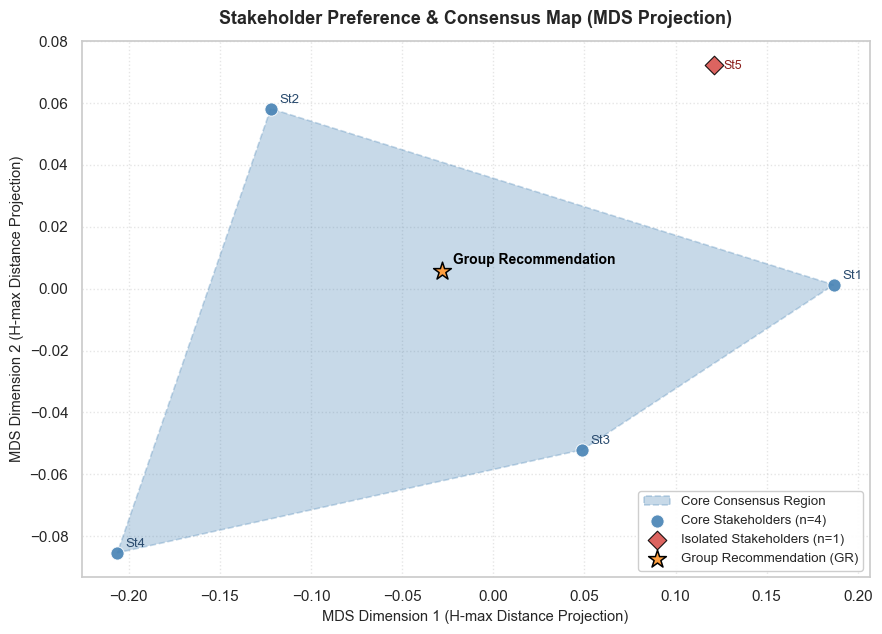

In [5]:
print("IFVs Ratings Matrix (Filled with Predicted Ratings):")
display(df_predicted_ifv.map(format_ifv))

# Formulate the Group Recommendation (GR) by aggregating the IFV ratings of core stakeholders
gr_series = calculate_group_recommendation(df_predicted_ifv, core_list)
print("\nIFV Group Recommendation:")
display(pd.DataFrame(gr_series, columns=['GR']).T.map(format_ifv))

# De-normalize the Group Recommendation IFVs back to crisp numeric values for stakeholder readability
gr_num = gr_series.map(lambda x: round(defuzzify_to_numeric(x, min_scale=1.0, max_scale=5.0), 0))
print("\nNumeric Group Recommendation:")
display(pd.DataFrame(gr_num, columns=['GR']).T)

# Apply Multidimensional Scaling (MDS) to visualize the spatial distribution of preferences and the GR
dist_for_mds, _ = get_similarity_matrices(df_predicted_ifv)
plot_stakeholder_map(dist_for_mds, core_list, isolated_list, gr_series, df_predicted_ifv, '../results/running_example_clustering_visualization.png')

### Phase 5: Consensus Measurement and Final Requirements Ranking
The final phase evaluates the overall **Consensus Degree (CD)**. If stakeholders adopt the recommendations, the consensus level improves. Once the consensus threshold is reached, the framework computes the Degree of Relation between the stakeholder assessments and the Reference Priority Matrix, assigning each requirement to its optimal prioritization class.

Initial Consensus Degree (cd1): 0.611
Updated Consensus Degree: 0.759 (Δ = +0.149)

Updated Similarity Matrix:


,St1,St2,St3,St4,St5
St1,1.00,0.68,0.88,0.43,0.78
St2,0.68,1.00,0.82,0.75,0.88
St3,0.88,0.82,1.00,0.75,0.90
St4,0.43,0.75,0.75,1.00,0.72
St5,0.78,0.88,0.90,0.72,1.00


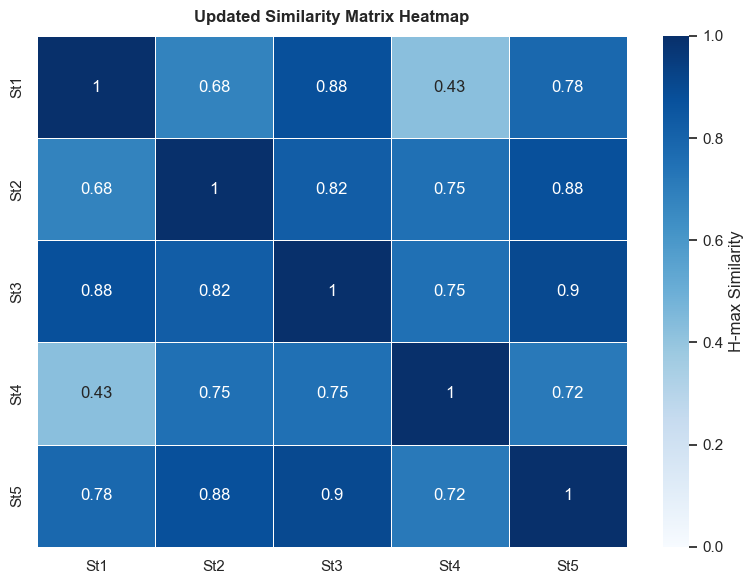


Requirements Classification Matrix (Degrees of Relation):


,Release1,Release2,Release3,Release4
Req1,0.76,0.64,0.40,0.20
Req2,0.52,0.64,0.56,0.44
Req3,0.49,0.72,0.78,0.69



Final Requirements Classification:
Req1 -> Release1
Req2 -> Release2
Req3 -> Release3


In [6]:
# Evaluate the initial global Consensus Degree (CD) among stakeholders prior to feedback
cd1 = calculate_consensus_degree(sim_matrix)
print(f"Initial Consensus Degree (cd1): {cd1:.3f}")

# Simulate preference modification by aligning an isolated stakeholder's ratings with the Group Recommendation
df_final_ifv = df_initial_ifv.copy()
df_final_ifv.loc['St5'] = gr_series

# Compute the updated pairwise similarity and the resulting improved Consensus Degree
_, sim_matrix_updated = get_similarity_matrices(df_final_ifv)
cd_updated = calculate_consensus_degree(sim_matrix_updated)
print(f"Updated Consensus Degree: {cd_updated:.3f} (Δ = +{cd_updated - cd1:.3f})")

print("\nUpdated Similarity Matrix:")
display(sim_matrix_updated.round(2))
plot_heatmap(sim_matrix_updated, title="Updated Similarity Matrix Heatmap", filename='../results/running_example_similarity_matrix_updated.png')

# Classify requirements into software releases based on the highest Degree of Relation to the expert benchmark
final_classification = calculate_classification(df_final_ifv, df_cpcrm_ifv)
print("\nRequirements Classification Matrix (Degrees of Relation):")
display(final_classification.style.format("{:.2f}").highlight_max(axis=1, props='font-weight: bold;'))

print("\nFinal Requirements Classification:")
results = final_classification.idxmax(axis=1)
for req, release in results.items():
    print(f"{req} -> {release}")